# Big Dipper
### Is this dip a buying opportunity, or a falling knife?

**Customer:** self-directed, long-term retail investors who see a stock fall and ask *"should I buy this?"*
**What it does:** scores the **business** (fundamentals) and the **price setup** (technicals) from 0-100, combines them with a
*quality gate* so a weak business can never be a "Buy", sizes the position for the investor's risk profile, explains every point, and
backtests the price-based rule honestly.

**How to use:** change the settings in section 1, then **Runtime > Run all** (Colab) or **Run All** (Jupyter). No other code needs editing.

*Educational project, not investment advice.*

In [1]:
# --- Setup (works locally and in Google Colab) ---
import os, subprocess, sys
REPO_URL = "https://github.com/tommieexteriors/big-dipper.git"   # <- set this once the GitHub repo exists

if "google.colab" in sys.modules and not os.path.exists("bigdipper"):
    subprocess.run(["git", "clone", REPO_URL, "big-dipper"], check=True)
    os.chdir("big-dipper")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from bigdipper import analyze_ticker, backtest_ticker, run_backtest, compare_naive_vs_filtered, sensitivity, BacktestParams, PROFILES, DEFAULT_SETTINGS
from bigdipper.data import download_ohlcv
from bigdipper.plots import plot_price, plot_waterfall, plot_backtest, plot_trade_returns
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams["figure.dpi"] = 110

## 1. Settings (the only cell you need to edit)

In [2]:
TICKER = "NKE"                 # any US stock symbol
PROFILE = "balanced"           # "conservative", "balanced" or "aggressive"
PERIOD = "10y"                 # how much price history to download (backtest uses all of it)
DIP_THRESHOLD = 0.15           # a 'dip' = this far below the 52-week high (0.15 = 15%)

SETTINGS = type(DEFAULT_SETTINGS)(dip_threshold=DIP_THRESHOLD)
print(f"Risk profile '{PROFILE}':", PROFILES[PROFILE])

Risk profile 'balanced': RiskProfile(name='balanced', min_fundamental_score=45, risk_budget=0.01, stop_loss=0.12, max_position=0.1)


## 2. Data collection and cleaning
Prices and volume come from Yahoo Finance (`yfinance`), adjusted for splits and dividends. Cleaning drops empty rows and duplicate dates,
forward-fills gaps of up to 3 days, and removes non-positive prices. Fundamentals are the *current* figures Yahoo reports; anything missing is
flagged and given neutral marks rather than guessed.

In [3]:
analysis, ohlcv, ind = analyze_ticker(TICKER, PROFILE, SETTINGS, period=PERIOD)
print(f"{analysis.name} ({analysis.ticker}), sector: {analysis.sector}")
print(f"{len(ohlcv):,} trading days from {ohlcv.index[0].date()} to {ohlcv.index[-1].date()}")
print("Missing values after cleaning:", int(ohlcv.isna().sum().sum()))
display(ohlcv.tail())

Nike, Inc. (NKE), sector: Consumer Cyclical
2,513 trading days from 2016-10-13 to 2026-10-13
Missing values after cleaning: 0


Price,Open,High,Low,Close,Volume
Date,,,,,
2026-10-07,34.390,34.530,33.810,34.360,37624400
2026-10-08,34.130,34.870,33.830,34.740,43802400
2026-10-09,34.580,35.090,34.100,34.710,27456900
2026-10-12,34.700,35.350,34.380,35.350,23656600
2026-10-13,35.500,35.840,35.155,35.640,20794718


## 3. Where is the stock relative to its high?

Price $35.64  |  52-week high $67.46  |  -47.2% from the high


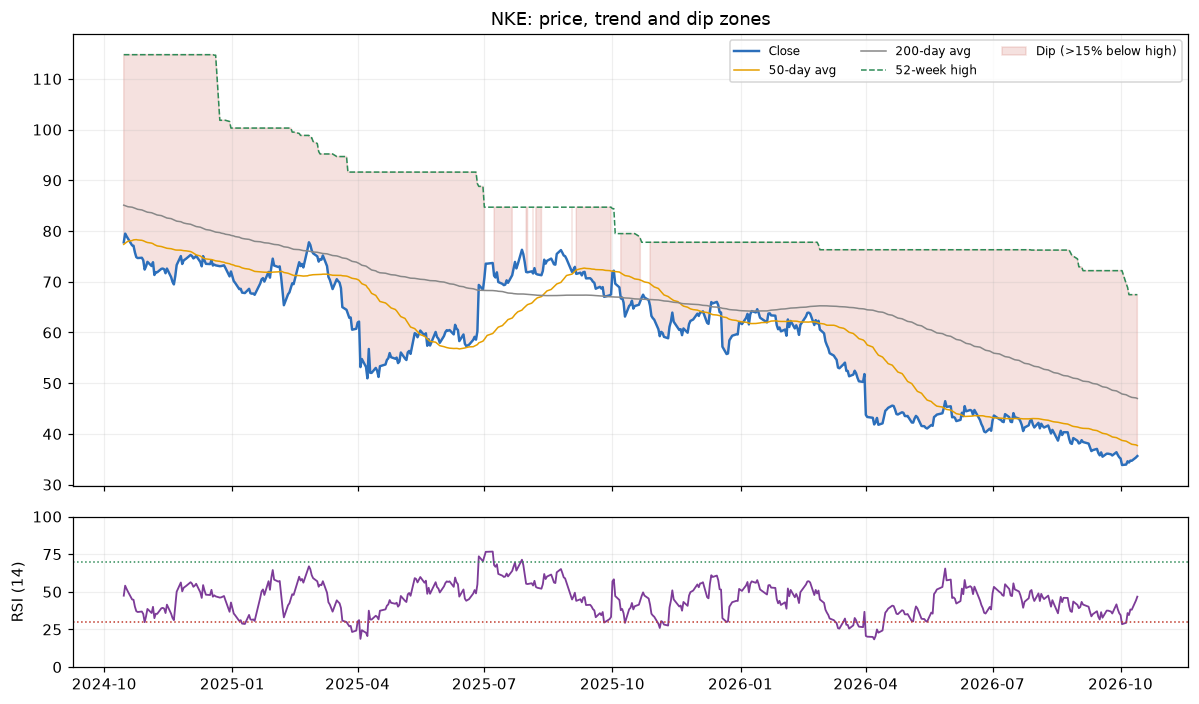

In [4]:
print(f"Price ${analysis.price:,.2f}  |  52-week high ${analysis.high_52w:,.2f}  |  {analysis.drawdown:.1%} from the high")
fig = plot_price(ind, TICKER, DIP_THRESHOLD); plt.show()

## 4. Fundamental analysis: is the business healthy? (0-100)
Four pillars, 25 points each: **valuation** (P/E, PEG), **profitability** (ROE, profit margin), **growth** (revenue, earnings),
**financial health** (debt-to-equity, free-cash-flow yield). Thresholds are in `bigdipper/fundamentals.py` and justified in `docs/METHODOLOGY.md`.

In [5]:
fund = pd.DataFrame([c.to_dict() for c in analysis.components if c.group == "fundamental"])
display(fund[["name", "value", "points", "max_points", "note"]])
print(f"Fundamental score: {analysis.fund_score:.0f} / 100")

,name,value,points,max_points,note
0,P/E ratio,P/E 21.1,9.500,12.500,Cheap relative to earnings.
1,PEG ratio,PEG 1.47,9.600,12.500,Price is reasonable for its growth.
2,Return on equity,22%,12.500,12.500,Earns strong returns on shareholder capital.
3,Profit margin,7%,4.200,12.500,Thin or negative margins.
4,Revenue growth,-4%,0.400,12.500,Flat or shrinking.
5,Earnings growth,-2%,3.300,12.500,Flat or shrinking.
6,Debt-to-equity,0.73x,10.600,12.500,Manageable debt.
7,Free-cash-flow yield,3%,8.300,12.500,Generates real cash relative to its price.


Fundamental score: 58 / 100


## 5. Technical analysis: is the price setup a good entry? (0-100)
Four methods, 25 points each: **RSI** (oversold?), **Bollinger Bands** (stretched below normal range?), **200-day trend** (is the long-term
uptrend intact or broken?), and **volume** (is there a capitulation spike, or quiet drift?).

In [6]:
tech = pd.DataFrame([c.to_dict() for c in analysis.components if c.group == "technical"])
display(tech[["name", "value", "points", "max_points", "note"]])
print(f"Technical score: {analysis.tech_score:.0f} / 100")

,name,value,points,max_points,note
0,RSI (14),RSI 47,4.000,25,Not oversold yet; the selling may not be exhau...
1,Bollinger Bands,%B 0.58,0.000,25,Price is still inside its normal 20-day range.
2,Long-term trend (200-day),-24% vs 200-day avg,4.900,25,Price is below its 200-day average; the trend ...
3,Volume (capitulation),0.9x normal volume,0.000,25,No volume spike; the decline is quiet drift.


Technical score: 9 / 100


## 6. The decision
`combined = 50% business + 50% setup`. **Gate:** if the business score is below the risk profile's minimum, the answer is *Avoid* no matter how
oversold the chart looks. Otherwise: **60+ = Buy the Dip**, **45-60 = Wait**, **below 45 = Avoid**. A buy comes with a position size and stop-loss
derived from the investor's risk budget.

### NKE: **Avoid (Falling Knife)**

NKE is 47% below its 52-week high. Business quality scores 58/100: strongest on Return on equity (22%), weakest on Revenue growth (-4%). The price setup scores 9/100: best signal is Long-term trend (200-day) (-24% vs 200-day avg), weakest is Bollinger Bands (%B 0.58). Verdict: AVOID. The combined score of 34 is below 45; neither the business nor the chart makes a convincing case.


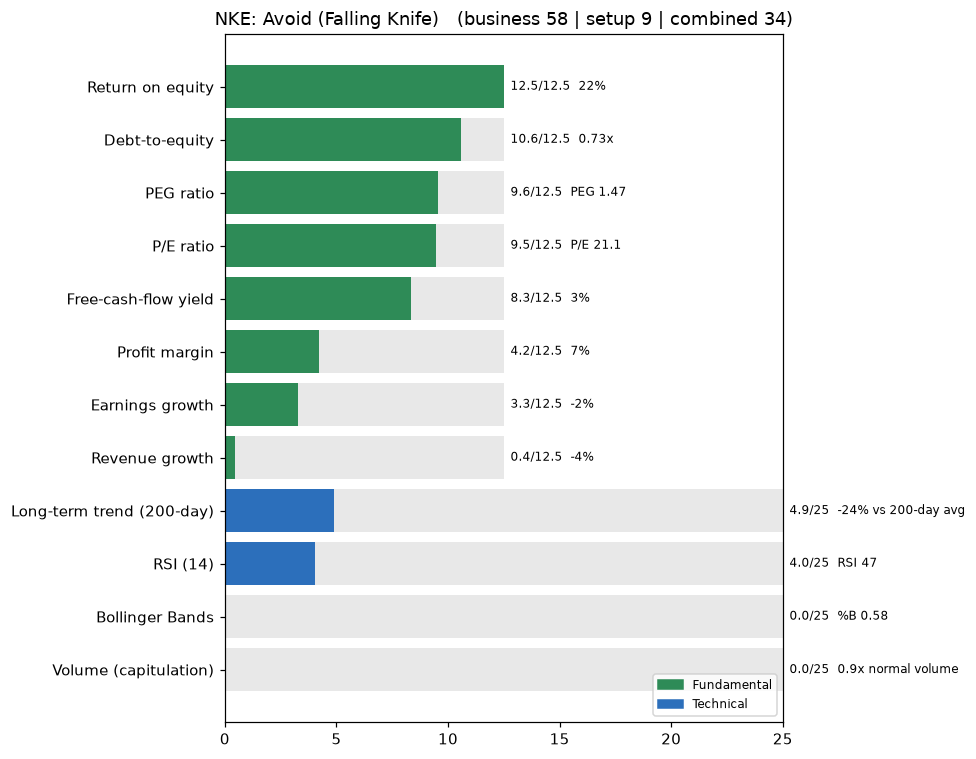

,verdict,position (% of portfolio),stop price
profile,,,
conservative,Avoid (Falling Knife),0.000,None
balanced,Avoid (Falling Knife),0.000,None
aggressive,Avoid (Falling Knife),0.000,None


In [7]:
display(Markdown(f"### {analysis.ticker}: **{analysis.verdict}**"))
print(analysis.explanation)
fig = plot_waterfall(analysis); plt.show()

from bigdipper.data import fetch_fundamentals
from bigdipper.decision import build_analysis
fundamentals = fetch_fundamentals(TICKER)
rows = []
for name in PROFILES:
    a = build_analysis(TICKER, ind.iloc[-1], fundamentals, name, SETTINGS)
    rows.append({"profile": name, "verdict": a.verdict, "position (% of portfolio)": a.position_size * 100, "stop price": a.stop_price})
display(pd.DataFrame(rows).set_index("profile"))

## 7. Strategy testing (price-based rule)
**Rule:** enter when the stock is at least `dip_threshold` below its 52-week high *and* the technical score is at least 55. Exit at a recovery target
(half the drop from the high), a stop-loss, or after 60 trading days. Signals use only data up to that day's close and trades execute at the **next day's open**
(no look-ahead bias). Costs: 5 bps per side.

> **Honest limitation:** Yahoo only provides *current* fundamentals, so the fundamental gate cannot be backtested without look-ahead bias.
> The backtest tests the technical half of Big Dipper; the fundamental score is a live overlay.

,Strategy,Buy & hold,S&P 500 (SPY)
total_return,0.026,-0.309,2.638
annual_volatility,0.245,0.333,0.186
max_drawdown,-0.394,-0.791,-0.337
trades,24.000,NaN,NaN
win_rate,0.500,NaN,NaN
avg_trade_return,0.012,NaN,NaN
exposure,0.455,NaN,NaN


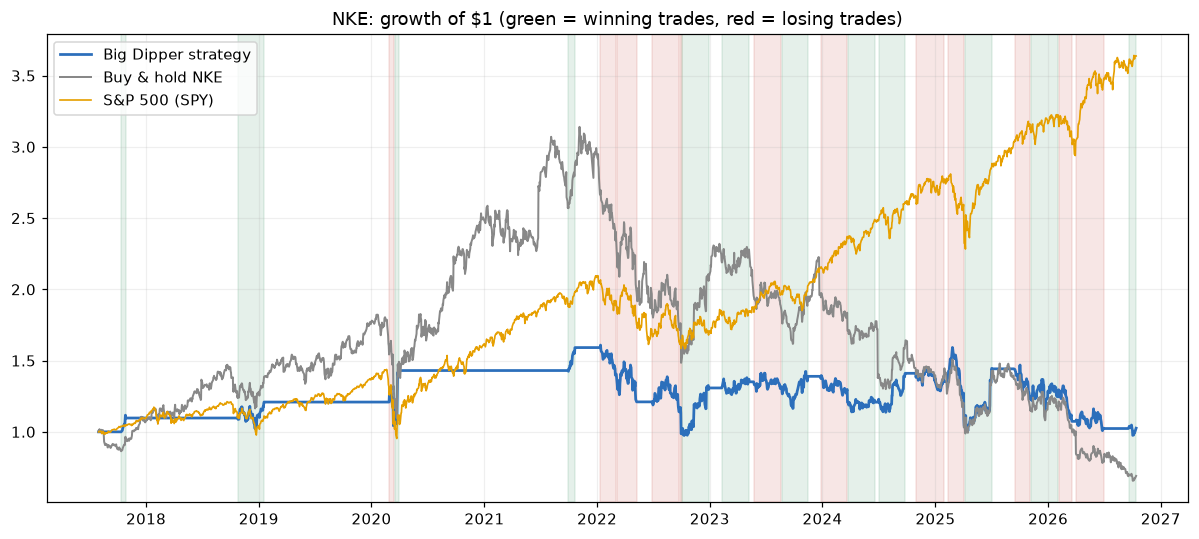

,entry_date,exit_date,entry,exit,return,days,reason
14,2024-03-25,2024-06-20,88.350,88.516,0.001,60,time stop
15,2024-07-01,2024-09-25,71.186,83.200,0.168,60,time stop
16,2024-10-30,2025-01-29,73.871,70.869,-0.042,60,time stop
17,2025-02-10,2025-04-04,66.024,50.917,-0.230,38,stop-loss
18,2025-04-07,2025-07-03,53.002,73.454,0.384,60,recovery target
19,2025-09-15,2025-11-04,70.844,60.428,-0.148,36,stop-loss
20,2025-11-05,2026-02-03,59.324,60.190,0.014,60,time stop
21,2026-02-04,2026-03-19,60.131,51.880,-0.138,30,stop-loss
22,2026-04-02,2026-06-30,42.917,40.946,-0.047,60,time stop
23,2026-09-21,2026-10-13,35.520,35.625,0.002,17,open at end


In [8]:
PARAMS = BacktestParams(dip_threshold=DIP_THRESHOLD)
result = backtest_ticker(TICKER, PARAMS, period=PERIOD)
display(result.summary())
fig = plot_backtest(result); plt.show()
display(result.trades.tail(10))

## 8. Does the technical filter actually help?
Single stocks have too few trades to judge. Here we pool trades across a basket of large companies and compare **"buy every dip"** against **Big Dipper's filter**.
(Survivorship bias warning: the basket is today's large caps, so companies that collapsed are missing, which flatters both versions.)

In [9]:
BASKET = "AAPL MSFT NVDA AMZN GOOGL META TSLA NKE DIS INTC PFE KO PEP WMT HD JPM BAC XOM CVX BA CAT MMM T VZ CSCO ORCL ADBE CRM AMD QCOM TXN MCD SBUX TGT COST LOW UNH JNJ MRK".split()
basket_data = {t: download_ohlcv(t, PERIOD) for t in BASKET}
comparison = compare_naive_vs_filtered(basket_data, PARAMS)
display(comparison)

,trades,win_rate,avg_return_per_trade,median_return_per_trade,worst_trade,avg_days_held
Naive: buy every dip,"1,022.000",0.601,0.037,0.072,-0.358,33.750
Big Dipper technical filter,782.000,0.607,0.041,0.077,-0.281,34.063


In [10]:
# Higher technical-score cut-offs: fewer trades, and (in this sample) a higher win rate and smaller worst loss
rows = {}
for m in [None, 45, 55, 65, 75]:
    from dataclasses import replace
    c = compare_naive_vs_filtered(basket_data, replace(PARAMS, entry_min_tech=m)).iloc[1 if m is not None else 0]
    rows["no filter" if m is None else f"score >= {m}"] = c
display(pd.DataFrame(rows).T)

,trades,win_rate,avg_return_per_trade,median_return_per_trade,worst_trade,avg_days_held
no filter,"1,022.000",0.601,0.037,0.072,-0.358,33.750
score >= 45,889.000,0.595,0.040,0.073,-0.339,33.990
score >= 55,782.000,0.607,0.041,0.077,-0.281,34.063
score >= 65,591.000,0.628,0.045,0.085,-0.261,33.481
score >= 75,361.000,0.598,0.036,0.069,-0.244,33.742


## 9. Sensitivity: how fragile are the results to our assumptions?

In [11]:
grid = sensitivity(ohlcv, PARAMS)
display(grid)
display(grid.pivot(index="dip_threshold", columns="min_tech_score", values="total_return").style.format("{:.1%}").set_caption(f"{TICKER}: strategy total return by dip threshold and technical cut-off"))

,dip_threshold,min_tech_score,trades,win_rate,total_return,max_drawdown
0,0.100,none,43,0.488,-0.628,-0.841
1,0.100,45,36,0.500,-0.458,-0.695
2,0.100,55,32,0.531,-0.075,-0.477
3,0.100,65,26,0.615,0.605,-0.332
4,0.150,none,33,0.455,-0.492,-0.743
5,0.150,45,28,0.464,-0.436,-0.668
6,0.150,55,24,0.500,0.026,-0.394
7,0.150,65,17,0.588,0.772,-0.261
8,0.200,none,27,0.370,-0.577,-0.734
9,0.200,45,23,0.435,-0.452,-0.600


min_tech_score,45,55,65,none
dip_threshold,,,,
0.100000,-45.8%,-7.5%,60.5%,-62.8%
0.150000,-43.6%,2.6%,77.2%,-49.2%
0.200000,-45.2%,-19.7%,54.8%,-57.7%
0.250000,-17.5%,25.7%,87.1%,-39.3%


## 10. Today's biggest dippers (market screener)
The same engine run across the whole S&P 500. This is what feeds the Big Dipper website: a list of every stock that is down, each clickable
to its score and explanation. Set `RUN_SCREEN = True` to scan (about 30 seconds).

In [12]:
RUN_SCREEN = False
if RUN_SCREEN:
    from bigdipper import run_screen
    payload = run_screen("web/data/dippers.json")
    s = pd.DataFrame([{"ticker": x["ticker"], "name": x["name"], "from high": x["drawdown"], "1-day": x["day_change"],
                       "business": x["fund_score"], "setup": x["tech_score"], "verdict": x["verdicts"][PROFILE]["verdict"]} for x in payload["stocks"]])
    display(s.head(25))
    print(s["verdict"].value_counts())

## 11. Limitations and risks
* **Fundamentals are not backtested.** Only current fundamentals are available; the backtest covers the technical rule only.
* **Survivorship bias.** Basket and screener use today's index members.
* **Bull-market sample.** Ten years of mostly rising markets flatter any buy-the-dip rule. Dips in 2008 or 2000-02 looked very different.
* **Thresholds are judgment calls.** See the sensitivity tables; results move when the thresholds move.
* **Yahoo data quality.** Free data can be delayed, restated, or missing; missing fundamentals get neutral marks and a warning.
* **Not advice.** The tool ranks and explains; the investor decides.